<a href="https://colab.research.google.com/github/YeweonJung/workshop/blob/main/PKPD_R_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PK/PD 기초와 R 기반 모델링 실습

R에 기본으로 들어 있는 테오필린(`Theoph`) 자료와 직접 만든 시뮬레이션 자료로 아래 순서를 한 번씩 해 본다.

1. 자료 확인
2. 비구획분석(NCA)
3. 개인별 1-구획 모형 적합
4. 집단약동학(PopPK) 모형 적합 (`nlme`, 비선형 혼합효과모형)
5. 적합도 진단(GOF)과 시각적 예측 점검(VPC)
6. 반복 투여 시뮬레이션으로 용량 비교
7. PK/PD 연결: Emax 모형 적합과 목표 수용체 점유율에 맞춘 용량 찾기

**런타임 유형을 R로 바꾼 뒤 실행한다.** (런타임 → 런타임 유형 변경 → R)
추가 설치가 필요 없는 패키지(`nlme`, `ggplot2`)만 사용했다.

In [1]:
library(nlme)
library(ggplot2)
set.seed(2026)
options(repr.plot.width = 9, repr.plot.height = 5.5, digits = 4)
theme_set(theme_bw(base_size = 13))
R.version.string
packageVersion("nlme"); packageVersion("ggplot2")

[1] "R version 4.6.1 (2026-06-24)"

[1] ‘3.1.171’

[1] ‘4.0.3’

## 1. 자료 확인

`Theoph`: 성인 12명에게 테오필린을 1회 경구 투여하고 24시간 동안 11번 채혈한 자료 (Boeckmann, Sheiner, Beal 1994).

| 변수 | 의미 | 단위 |
|---|---|---|
| Subject | 대상자 | |
| Wt | 체중 | kg |
| Dose | 체중당 투여량 | mg/kg |
| Time | 투여 후 시간 | h |
| conc | 혈중 농도 | mg/L |

In [2]:
d <- as.data.frame(Theoph)
d$Subject <- factor(as.character(d$Subject), levels = as.character(1:12))
str(d)
head(d, 12)

# 대상자별 체중과 용량
unique(d[, c("Subject", "Wt", "Dose")])

'data.frame':	132 obs. of  5 variables:
 $ Subject: Factor w/ 12 levels "1","2","3","4",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ Wt     : num  79.6 79.6 79.6 79.6 79.6 79.6 79.6 79.6 79.6 79.6 ...
 $ Dose   : num  4.02 4.02 4.02 4.02 4.02 4.02 4.02 4.02 4.02 4.02 ...
 $ Time   : num  0 0.25 0.57 1.12 2.02 ...
 $ conc   : num  0.74 2.84 6.57 10.5 9.66 8.58 8.36 7.47 6.89 5.94 ...


,Subject,Wt,Dose,Time,conc
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,79.6,4.02,0.00,0.74
2,1,79.6,4.02,0.25,2.84
3,1,79.6,4.02,0.57,6.57
4,1,79.6,4.02,1.12,10.50
5,1,79.6,4.02,2.02,9.66
6,1,79.6,4.02,3.82,8.58
7,1,79.6,4.02,5.10,8.36
8,1,79.6,4.02,7.03,7.47
9,1,79.6,4.02,9.05,6.89


,Subject,Wt,Dose
,<fct>,<dbl>,<dbl>
1,1,79.6,4.02
12,2,72.4,4.40
23,3,70.5,4.53
34,4,72.7,4.40
45,5,54.6,5.86
56,6,80.0,4.00
67,7,64.6,4.95
78,8,70.5,4.53
89,9,86.4,3.10


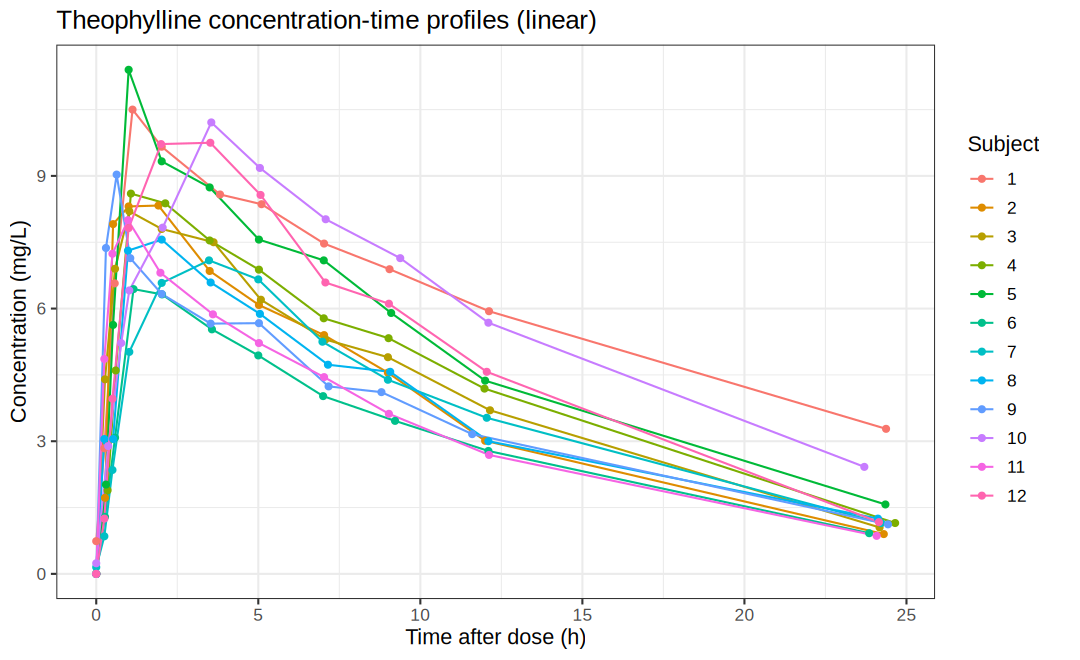

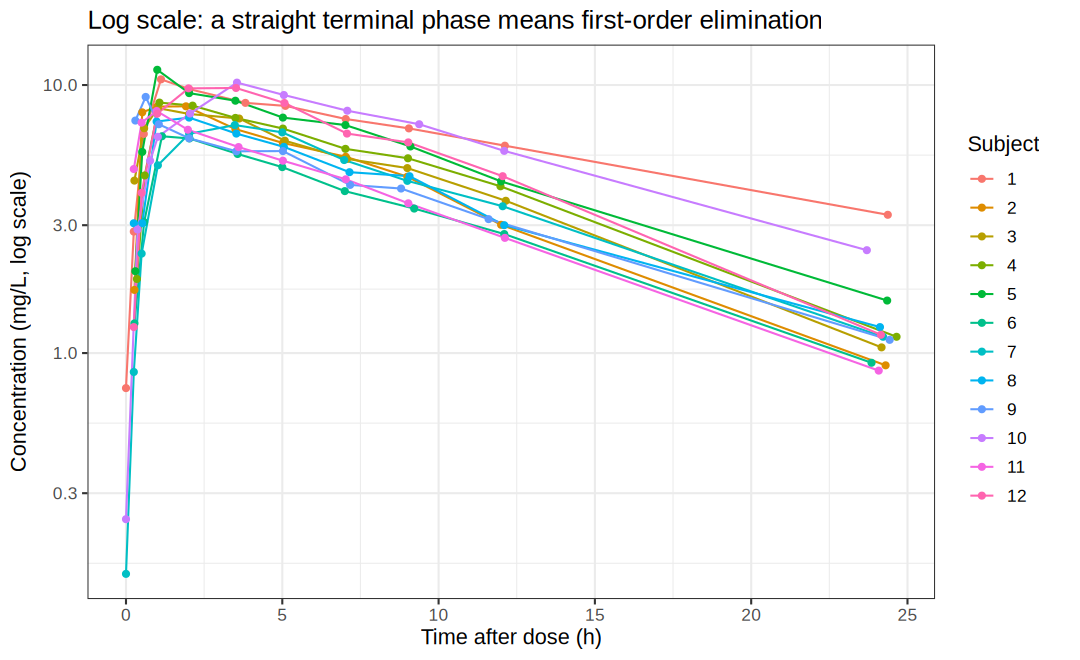

In [3]:
ggplot(d, aes(Time, conc, group = Subject, colour = Subject)) +
  geom_line() + geom_point(size = 1.5) +
  labs(x = "Time after dose (h)", y = "Concentration (mg/L)", title = "Theophylline concentration-time profiles (linear)")

ggplot(subset(d, conc > 0), aes(Time, conc, group = Subject, colour = Subject)) +
  geom_line() + geom_point(size = 1.5) + scale_y_log10() +
  labs(x = "Time after dose (h)", y = "Concentration (mg/L, log scale)", title = "Log scale: a straight terminal phase means first-order elimination")

## 2. 비구획분석 (NCA)

모형을 가정하지 않고 관측값에서 바로 계산하는 방법이다.

- Cmax, Tmax: 관측 최고 농도와 그 시점
- AUC(0-last): 상승 구간은 선형 사다리꼴, 하강 구간은 로그 사다리꼴(linear-up/log-down)
- λz: 말기 3개 이상 점에 로그-선형 회귀. 수정 R²가 가장 큰 구간을 고른다 (Tmax 이후 점만 사용)
- AUC(0-∞) = AUC(0-last) + C_last / λz
- t½ = ln2 / λz, CL/F = Dose / AUC(0-∞), Vz/F = CL/F / λz

용량이 mg/kg이므로 CL/F 단위는 L/h/kg, Vz/F는 L/kg이 된다.

In [4]:
auc_lin_log <- function(t, c) {
  auc <- 0
  for (i in 2:length(t)) {
    dt <- t[i] - t[i - 1]
    if (c[i] < c[i - 1] && c[i] > 0 && c[i - 1] > 0) {
      auc <- auc + (c[i - 1] - c[i]) * dt / log(c[i - 1] / c[i])   # 로그 사다리꼴
    } else {
      auc <- auc + (c[i] + c[i - 1]) * dt / 2                       # 선형 사다리꼴
    }
  }
  auc
}

pick_lambda_z <- function(t, c, tmax) {
  ok <- which(t > tmax & c > 0)
  n  <- length(ok)
  best <- NULL
  for (k in 3:n) {
    idx <- tail(ok, k)
    fit <- lm(log(c[idx]) ~ t[idx])
    r2a <- summary(fit)$adj.r.squared
    lz  <- -coef(fit)[2]
    # 수정 R2가 최대값과 0.0001 이내이면 점을 더 많이 쓰는 쪽을 택한다
    if (lz > 0 && (is.null(best) || r2a >= best$r2a - 1e-4)) {
      best <- list(lz = unname(lz), r2a = r2a, npts = k)
    }
  }
  best
}

nca_one <- function(df) {
  df   <- df[order(df$Time), ]
  t    <- df$Time; c <- df$conc; dose <- df$Dose[1]
  cmax <- max(c); tmax <- t[which.max(c)]
  auclast <- auc_lin_log(t, c)
  lz   <- pick_lambda_z(t, c, tmax)
  aucinf <- auclast + tail(c, 1) / lz$lz
  data.frame(Subject = df$Subject[1], Wt = df$Wt[1], Dose = dose,
             Cmax = cmax, Tmax = tmax, AUClast = auclast, AUCinf = aucinf,
             pct_extrap = 100 * (aucinf - auclast) / aucinf,
             lambda_z = lz$lz, n_lz = lz$npts, adjR2 = lz$r2a,
             t_half = log(2) / lz$lz,
             CL_F = dose / aucinf,
             Vz_F = dose / aucinf / lz$lz)
}

nca <- do.call(rbind, lapply(split(d, d$Subject), nca_one))
rownames(nca) <- NULL
print(nca, digits = 3)

   Subject   Wt Dose  Cmax Tmax AUClast AUCinf pct_extrap lambda_z n_lz adjR2
1        1 79.6 4.02 10.50 1.12   147.2  214.9      31.49   0.0485    3 1.000
2        2 72.4 4.40  8.33 1.92    88.7   97.4       8.88   0.1041    4 0.996
3        3 70.5 4.53  8.20 1.02    95.9  106.1       9.66   0.1024    3 0.999
4        4 72.7 4.40  8.60 1.07   102.6  114.2      10.14   0.0993    3 0.998
5        5 54.6 5.86 11.40 1.00   118.2  136.3      13.30   0.0866    4 0.998
6        6 80.0 4.00  6.44 1.15    71.7   82.2      12.75   0.0878    7 0.998
7        7 64.6 4.95  7.09 3.48    88.0  101.0      12.89   0.0883    4 0.998
8        8 70.5 4.53  7.56 2.02    86.8  102.2      15.02   0.0815    6 0.989
9        9 86.4 3.10  9.03 0.63    83.9   97.5      13.93   0.0825    3 0.999
10      10 58.2 5.50 10.21 3.55   135.6  167.9      19.23   0.0750    3 0.999
11      11 65.0 4.92  8.00 0.98    77.9   86.9      10.37   0.0955    3 1.000
12      12 60.5 5.30  9.75 3.52   115.2  125.8       8.43   0.11

In [5]:
# 요약 통계: 산술평균, SD, 기하평균, CV%
summ <- function(x) c(mean = mean(x), sd = sd(x), median = median(x),
                      geomean = exp(mean(log(x))), CV_pct = 100 * sd(x) / mean(x))
nca_summary <- t(sapply(nca[, c("Cmax", "Tmax", "AUCinf", "t_half", "CL_F", "Vz_F")], summ))
round(nca_summary, 3)

# 외삽 비율이 20%를 넘으면 AUCinf 신뢰도가 떨어진다
subset(nca, pct_extrap > 20)

,mean,sd,median,geomean,CV_pct
Cmax,8.759,1.473,8.465,8.646,16.82
Tmax,1.788,1.112,1.135,1.515,62.20
AUCinf,119.365,38.192,104.140,114.814,32.00
t_half,8.180,2.115,7.871,7.987,25.86
CL_F,0.041,0.010,0.043,0.040,23.87
Vz_F,0.464,0.079,0.436,0.458,17.08


,Subject,Wt,Dose,Cmax,Tmax,AUClast,AUCinf,pct_extrap,lambda_z,n_lz,adjR2,t_half,CL_F,Vz_F
,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,79.6,4.02,10.5,1.12,147.2,214.9,31.49,0.04846,3,1,14.3,0.0187,0.386


## 3. 개인별 1-구획 모형 적합

경구 1회 투여, 1차 흡수, 1차 소실 1-구획 모형:

$$C(t) = \frac{F \cdot Dose \cdot k_a}{V/F \cdot (k_a - k_e)} \left(e^{-k_e t} - e^{-k_a t}\right)$$

R의 `SSfol()`은 이 식을 로그 척도 모수 `lKe`, `lKa`, `lCl` (= log ke, log ka, log CL/F)로 쓰고 초기값도 알아서 잡는다.
대상자마다 따로 `nls`로 적합한 값(`nlsList`)은 다음 단계 집단모형의 초기값과 비교 기준이 된다.

In [6]:
fit_ind <- nlsList(conc ~ SSfol(Dose, Time, lKe, lKa, lCl) | Subject,
                   data = groupedData(conc ~ Time | Subject, data = d))
ind <- coef(fit_ind)
ind_par <- data.frame(Subject = rownames(ind),
                      ka = exp(ind$lKa), ke = exp(ind$lKe), CL_F = exp(ind$lCl))
ind_par$V_F    <- ind_par$CL_F / ind_par$ke
ind_par$t_half <- log(2) / ind_par$ke
print(ind_par, digits = 3)

# NCA CL/F와 모형 CL/F 비교
cmp <- merge(nca[, c("Subject", "CL_F")], ind_par[, c("Subject", "CL_F")],
             by = "Subject", suffixes = c("_NCA", "_model"))
cmp
cor(cmp$CL_F_NCA, cmp$CL_F_model)

   Subject    ka     ke   CL_F   V_F t_half
1        6 1.164 0.0995 0.0511 0.514   6.96
2        7 0.680 0.1022 0.0516 0.505   6.78
3        8 1.376 0.0920 0.0465 0.505   7.54
4       11 3.849 0.0981 0.0572 0.583   7.06
5        3 2.454 0.0814 0.0396 0.486   8.51
6        2 1.943 0.1017 0.0448 0.440   6.82
7        4 1.171 0.0875 0.0374 0.428   7.92
8        9 8.866 0.0866 0.0327 0.377   8.00
9       12 0.833 0.1056 0.0420 0.398   6.57
10      10 0.696 0.0740 0.0324 0.439   9.37
11       1 1.777 0.0540 0.0199 0.369  12.85
12       5 1.472 0.0884 0.0436 0.493   7.84


Subject,CL_F_NCA,CL_F_model
<fct>,<dbl>,<dbl>
1,0.01870,0.01992
10,0.03277,0.03244
11,0.05662,0.05725
12,0.04212,0.04200
2,0.04518,0.04477
3,0.04268,0.03956
4,0.03852,0.03740
5,0.04299,0.04360
6,0.04868,0.05114


[1] 0.9872

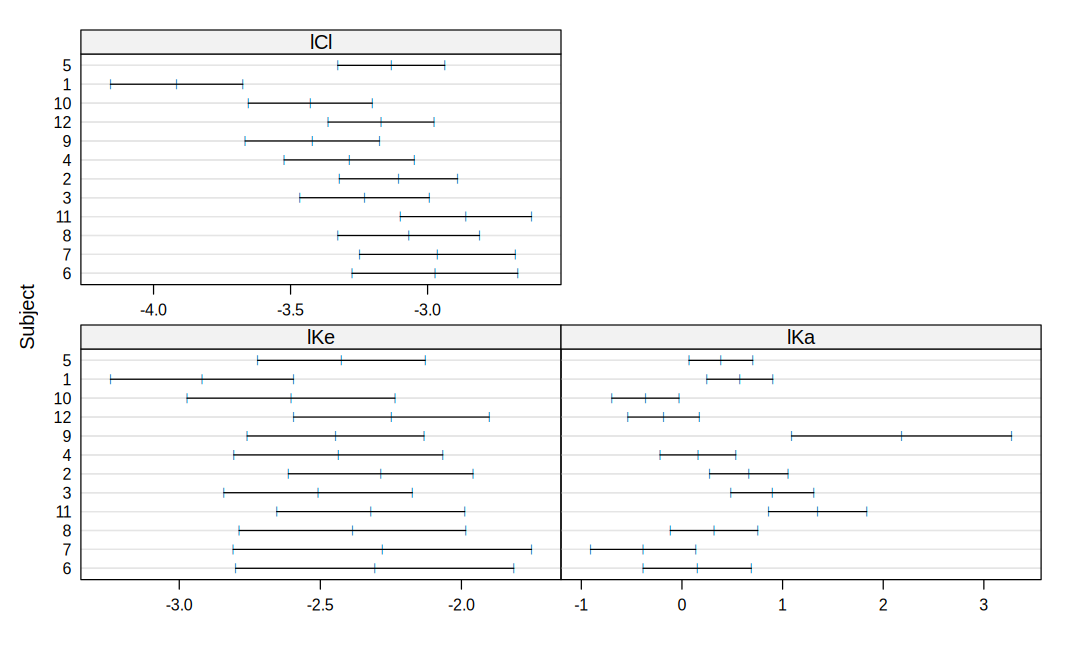

In [7]:
plot(intervals(fit_ind))   # 개인별 모수와 95% 신뢰구간. 대상자 간 차이가 큰 모수가 무엇인지 본다

## 4. 집단약동학 모형 (nlme)

개인별 모수를 집단 전형값(고정효과, θ)과 개인 편차(무작위효과, η)로 나눈다.

$$\log CL_i = \theta_{CL} + \eta_{CL,i}, \quad \eta \sim N(0, \omega^2)$$

로그 척도에서 정규분포를 가정하므로 원 척도에서는 로그정규분포가 되고, 개인 간 변동(IIV)은 대략 CV% ≈ √(exp(ω²) − 1) × 100 으로 읽는다.

비교할 모형
- M1: ka, CL에 무작위효과 (Pinheiro & Bates 책의 기본 모형)
- M2: ke, ka, CL 셋 다 무작위효과
- M3: M1에 체중을 CL 공변량으로 추가

`nlme`는 FOCE와 비슷한 선형화 기반 추정(Lindstrom-Bates)을 쓴다. NONMEM의 FOCE-I와 숫자가 완전히 같지는 않지만 개념은 같다.

In [8]:
gd <- groupedData(conc ~ Time | Subject, data = d)

m1 <- nlme(conc ~ SSfol(Dose, Time, lKe, lKa, lCl),
           data = gd,
           fixed  = lKe + lKa + lCl ~ 1,
           random = pdDiag(lKa + lCl ~ 1),
           start  = fixef(nlme(fit_ind, random = pdDiag(lKa + lCl ~ 1))))

m2 <- tryCatch(
  nlme(conc ~ SSfol(Dose, Time, lKe, lKa, lCl), data = gd,
       fixed = lKe + lKa + lCl ~ 1, random = pdDiag(lKe + lKa + lCl ~ 1),
       start = fixef(m1)),
  error = function(e) { message("M2 수렴 실패: ", conditionMessage(e)); NULL })

summary(m1)

Nonlinear mixed-effects model fit by maximum likelihood
  Model: conc ~ SSfol(Dose, Time, lKe, lKa, lCl) 
  Data: gd 
  AIC   BIC logLik
  366 383.3   -177

Random effects:
 Formula: list(lKa ~ 1, lCl ~ 1)
 Level: Subject
 Structure: Diagonal
           lKa    lCl Residual
StdDev: 0.6438 0.1669   0.7092

Fixed effects:  lKe + lKa + lCl ~ 1 
     Value Std.Error  DF t-value p-value
lKe -2.455   0.05249 118  -46.77  0.0000
lKa  0.466   0.19862 118    2.34  0.0208
lCl -3.227   0.06001 118  -53.78  0.0000
 Correlation: 
    lKe    lKa   
lKa -0.193       
lCl  0.540 -0.078

Standardized Within-Group Residuals:
    Min      Q1     Med      Q3     Max 
-3.2847 -0.4761  0.0000  0.3342  3.8501 

Number of Observations: 132
Number of Groups: 12 

In [9]:
if (!is.null(m2)) {
  print(anova(m1, m2))
  cat("\nM2의 ke 무작위효과 SD:", round(as.numeric(VarCorr(m2)["lKe", "StdDev"]), 4), "\n")
}

   Model df AIC   BIC logLik   Test  L.Ratio p-value
m1     1  6 366 383.3   -177                        
m2     2  7 368 388.2   -177 1 vs 2 0.003716  0.9514

M2의 ke 무작위효과 SD: 0 


`geom_smooth()` using formula = 'y ~ x'


,Value,Std.Error,DF,t-value,p-value
lKe,-2.4571,0.05275,117,-46.579,2.262e-77
lKa,0.4657,0.19816,117,2.350,2.045e-02
lCl.(Intercept),-3.2325,0.05703,117,-56.684,6.306e-87
lCl.Wtc,-0.0726,0.05107,117,-1.422,1.578e-01


,call,Model,df,AIC,BIC,logLik,Test,L.Ratio,p-value
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<dbl>
m1,"nlme.formula(model = conc ~ SSfol(Dose, Time, lKe, lKa, lCl), data = gd, fixed = lKe + lKa + lCl ~ 1, random = pdDiag(lKa + lCl ~ 1), start = fixef(nlme(fit_ind, random = pdDiag(lKa + lCl ~ 1))))",1,6,366.0,383.3,-177.0,,NA,NA
m3,"nlme.formula(model = conc ~ SSfol(Dose, Time, lKe, lKa, lCl), data = gd, fixed = list(lKe ~ 1, lKa ~ 1, lCl ~ Wtc), random = pdDiag(lKa + lCl ~ 1), start = c(fixef(m1)[1:2], fixef(m1)[3], 0))",2,7,366.2,386.4,-176.1,1 vs 2,1.875,0.1709


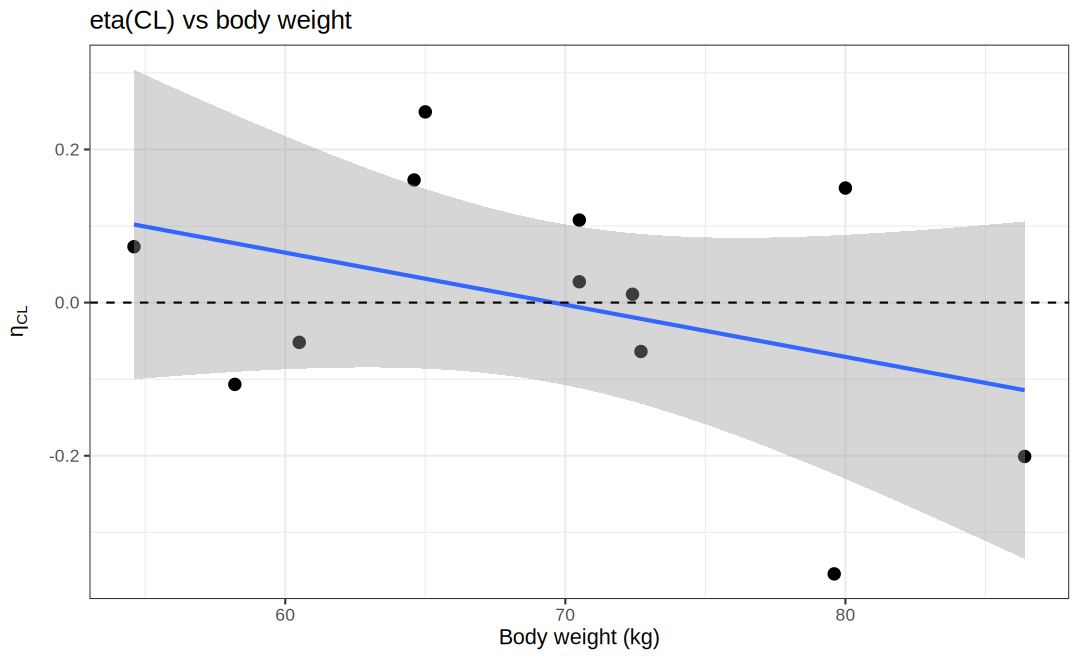

In [10]:
# 공변량 탐색: 개인 η(CL)와 체중의 관계
eta <- ranef(m1)
eta$Subject <- rownames(eta)
eta <- merge(eta, unique(d[, c("Subject", "Wt")]), by = "Subject")
ggplot(eta, aes(Wt, lCl)) + geom_point(size = 3) + geom_smooth(method = "lm", se = TRUE) +
  geom_hline(yintercept = 0, linetype = 2) +
  labs(x = "Body weight (kg)", y = expression(eta[CL]), title = "eta(CL) vs body weight")

# M3: log CL = θ1 + θ2 * (Wt - 70) / 10
d$Wtc <- (d$Wt - 70) / 10
gd <- groupedData(conc ~ Time | Subject, data = d)
m3 <- nlme(conc ~ SSfol(Dose, Time, lKe, lKa, lCl), data = gd,
           fixed  = list(lKe ~ 1, lKa ~ 1, lCl ~ Wtc),
           random = pdDiag(lKa + lCl ~ 1),
           start  = c(fixef(m1)[1:2], fixef(m1)[3], 0))
summary(m3)$tTable
anova(m1, m3)

용량이 이미 체중당(mg/kg)이라 CL/F 역시 체중당 값으로 나온다. 그래서 체중 공변량을 넣어도 크게 개선되지 않는 것이 자연스럽다.
아래부터는 M1을 최종 모형으로 쓴다. (위 `anova` 결과가 다르게 나오면 이 판단을 다시 본다.)

In [11]:
final <- m1
th <- fixef(final)
om <- as.numeric(VarCorr(final)[c("lKa", "lCl"), "StdDev"])
sig <- final$sigma

pop_tab <- data.frame(
  모수 = c("ka (1/h)", "ke (1/h)", "CL/F (L/h/kg)", "V/F (L/kg)", "t1/2 (h)",
          "IIV ka (CV%)", "IIV CL (CV%)", "잔차 SD (mg/L)"),
  추정값 = c(exp(th["lKa"]), exp(th["lKe"]), exp(th["lCl"]),
          exp(th["lCl"]) / exp(th["lKe"]), log(2) / exp(th["lKe"]),
          100 * sqrt(exp(om^2) - 1), sig))
pop_tab$추정값 <- round(pop_tab$추정값, 4)
pop_tab

# 고정효과 95% 신뢰구간 (원 척도)
ci <- intervals(final, which = "fixed")$fixed
round(exp(ci), 4)

모수,추정값
<chr>,<dbl>
ka (1/h),1.5929
ke (1/h),0.0859
CL/F (L/h/kg),0.0397
V/F (L/kg),0.4618
t1/2 (h),8.0699
IIV ka (CV%),71.6646
IIV CL (CV%),16.8069
잔차 SD (mg/L),0.7092


,lower,est.,upper
lKe,0.0775,0.0859,0.0952
lKa,1.0797,1.5929,2.3499
lCl,0.0353,0.0397,0.0446


## 5. 적합도 진단 (GOF)과 VPC

- 관측값(DV) vs 집단예측(PRED), 관측값 vs 개인예측(IPRED): y = x 선 주위에 고르게 퍼져 있어야 한다
- 잔차 vs 시간, 잔차 vs 예측값: 0 주위에 경향 없이 흩어져 있어야 한다
- 개인별 적합 곡선
- VPC: 최종 모형으로 가상 자료를 여러 번 만들어 관측 자료의 분위수(5, 50, 95%)가 시뮬레이션 범위 안에 드는지 본다

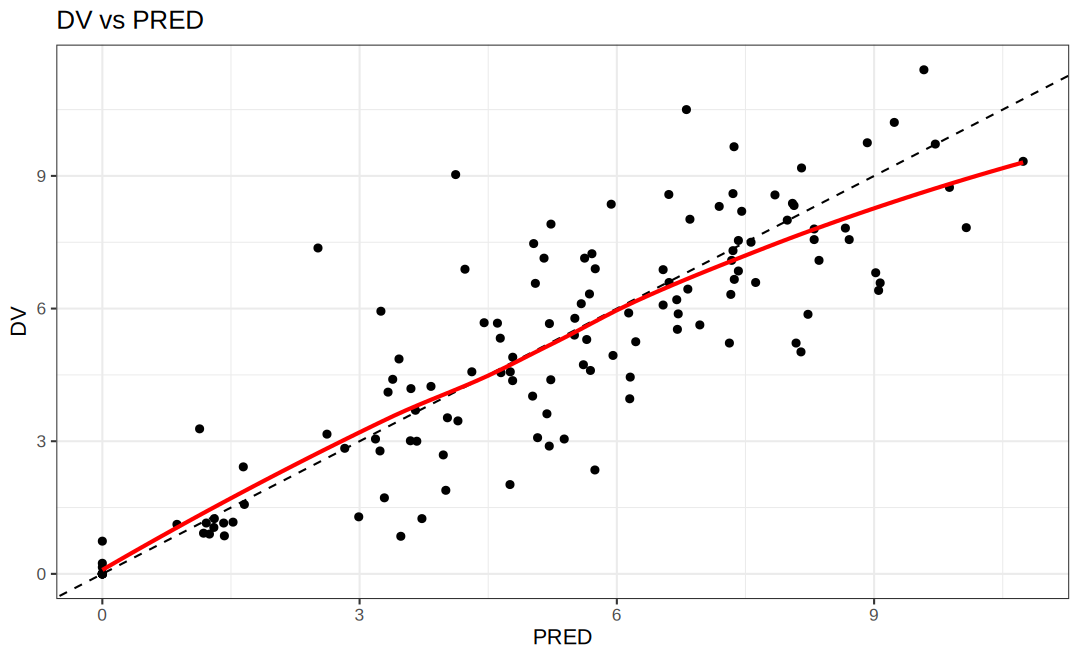

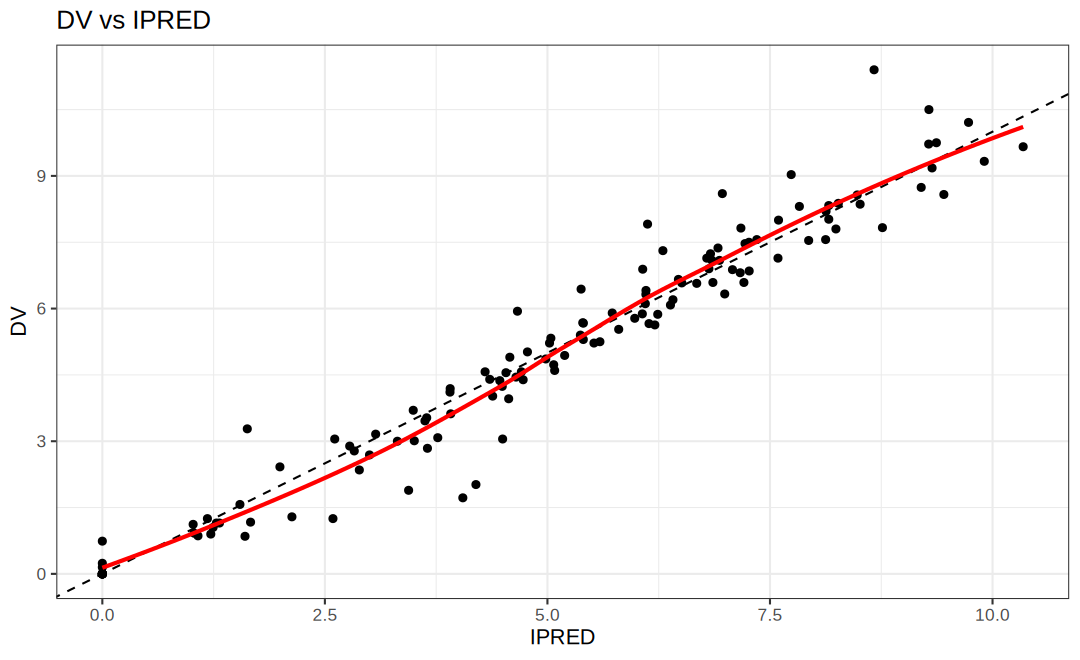

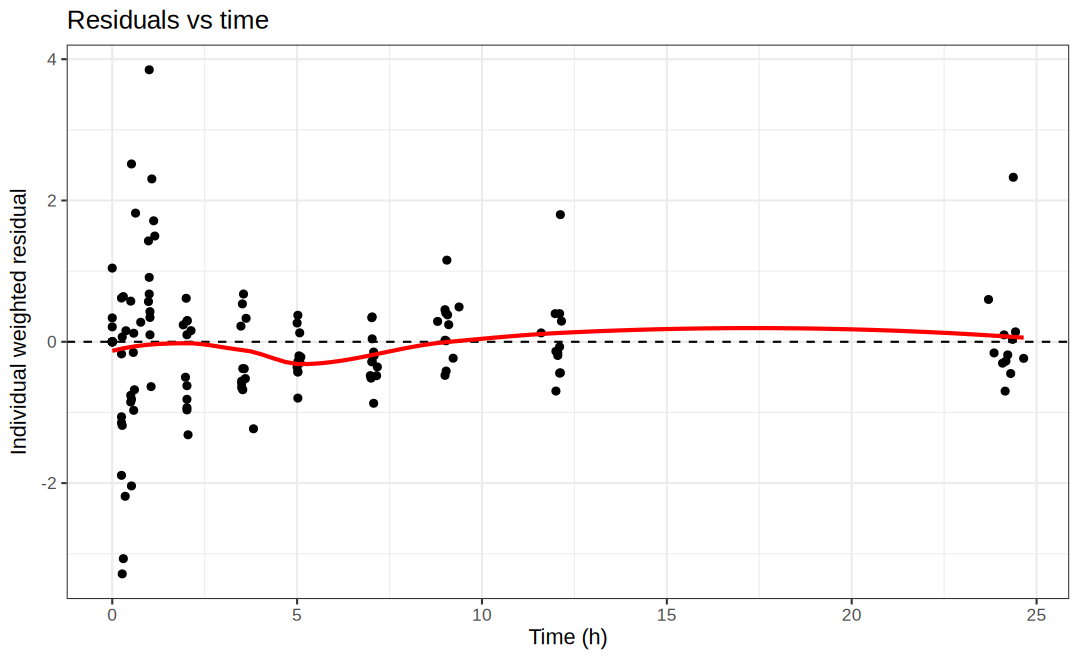

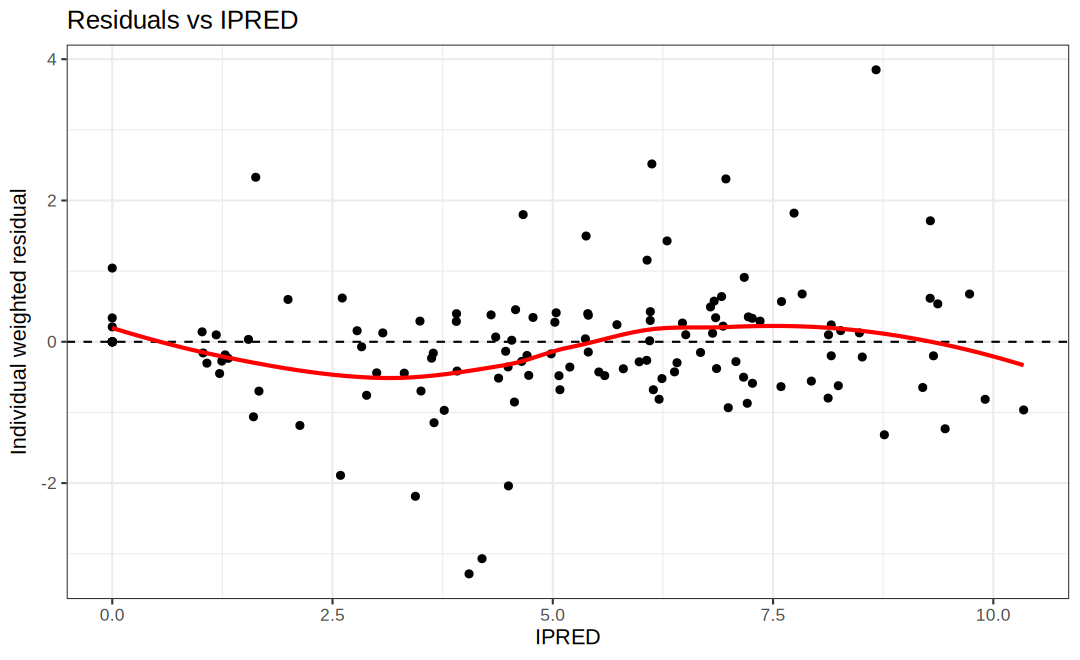

In [12]:
gof <- data.frame(d,
                  PRED  = fitted(final, level = 0),
                  IPRED = fitted(final, level = 1),
                  IRES  = resid(final, level = 1, type = "pearson"),
                  RES0  = resid(final, level = 0, type = "pearson"))

p1 <- ggplot(gof, aes(PRED, conc)) + geom_point() + geom_abline(linetype = 2) +
  geom_smooth(se = FALSE, method = "loess", formula = y ~ x, colour = "red") +
  labs(x = "PRED", y = "DV", title = "DV vs PRED")
p2 <- ggplot(gof, aes(IPRED, conc)) + geom_point() + geom_abline(linetype = 2) +
  geom_smooth(se = FALSE, method = "loess", formula = y ~ x, colour = "red") +
  labs(x = "IPRED", y = "DV", title = "DV vs IPRED")
p3 <- ggplot(gof, aes(Time, IRES)) + geom_point() + geom_hline(yintercept = 0, linetype = 2) +
  geom_smooth(se = FALSE, method = "loess", formula = y ~ x, colour = "red") +
  labs(x = "Time (h)", y = "Individual weighted residual", title = "Residuals vs time")
p4 <- ggplot(gof, aes(IPRED, IRES)) + geom_point() + geom_hline(yintercept = 0, linetype = 2) +
  geom_smooth(se = FALSE, method = "loess", formula = y ~ x, colour = "red") +
  labs(x = "IPRED", y = "Individual weighted residual", title = "Residuals vs IPRED")
print(p1); print(p2); print(p3); print(p4)

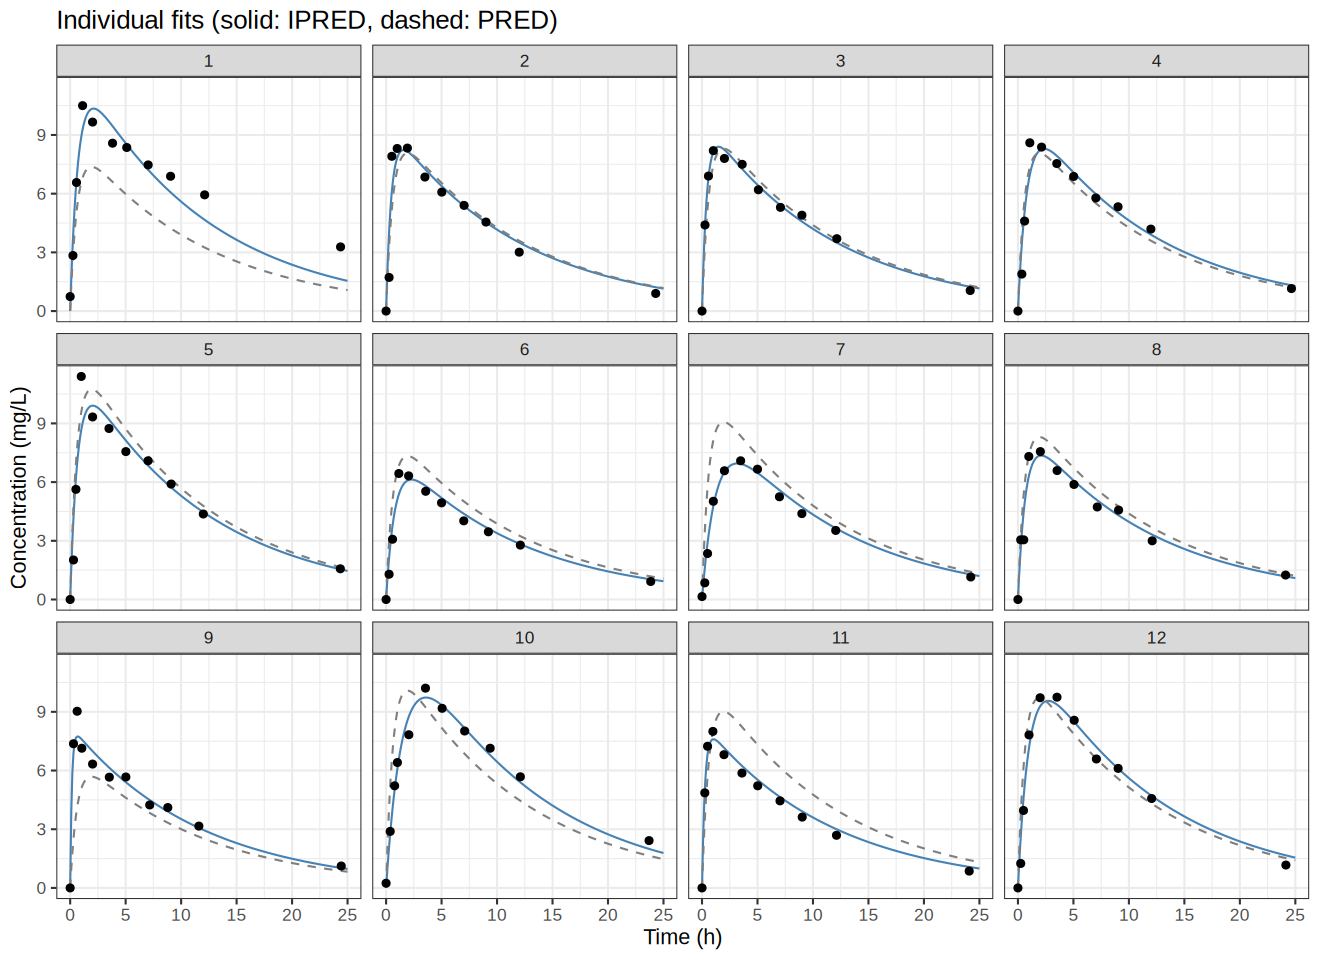

In [13]:
# 개인별 적합 곡선 (촘촘한 시간 격자에서 예측)
grid <- expand.grid(Time = seq(0, 25, by = 0.1), Subject = levels(d$Subject))
grid <- merge(grid, unique(d[, c("Subject", "Dose", "Wt", "Wtc")]), by = "Subject")
grid$IPRED <- predict(final, newdata = grid, level = 1)
grid$PRED  <- predict(final, newdata = grid, level = 0)
grid$Subject <- factor(grid$Subject, levels = levels(d$Subject))

options(repr.plot.width = 11, repr.plot.height = 8)
ggplot() +
  geom_line(data = grid, aes(Time, IPRED), colour = "steelblue") +
  geom_line(data = grid, aes(Time, PRED), colour = "grey50", linetype = 2) +
  geom_point(data = d, aes(Time, conc)) +
  facet_wrap(~ Subject, ncol = 4) +
  labs(x = "Time (h)", y = "Concentration (mg/L)", title = "Individual fits (solid: IPRED, dashed: PRED)")
options(repr.plot.width = 9, repr.plot.height = 5.5)

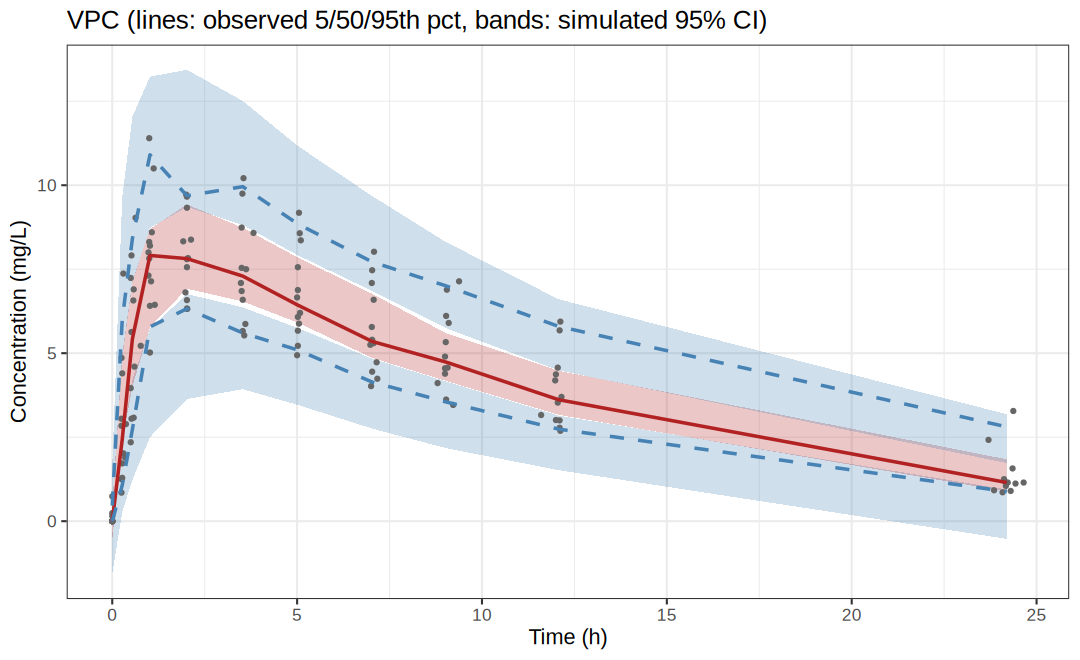

In [14]:
# 1-구획 경구 모형 함수 (반복 투여는 중첩 원리로 더한다)
conc_1cmt <- function(t, dose, ka, ke, V, tau = 0, n = 1) {
  out <- 0
  for (k in 0:(n - 1)) {
    tt <- pmax(t - k * tau, 0)   # 아직 투여 전이면 0시간으로 두어 기여분이 0이 되게 한다
    out <- out + dose * ka / (V * (ka - ke)) * (exp(-ke * tt) - exp(-ka * tt))
  }
  out
}

# VPC: 원 자료와 같은 설계(12명, 같은 용량, 같은 채혈 시각)로 500번 시뮬레이션
nsim <- 500
sim_once <- function() {
  s <- d[, c("Subject", "Time", "Dose")]
  ids <- levels(d$Subject)
  e_ka <- setNames(rnorm(length(ids), 0, om[1]), ids)
  e_cl <- setNames(rnorm(length(ids), 0, om[2]), ids)
  ka <- exp(th["lKa"] + e_ka[as.character(s$Subject)])
  ke <- exp(th["lKe"])
  cl <- exp(th["lCl"] + e_cl[as.character(s$Subject)])
  V  <- cl / ke
  ipred <- conc_1cmt(s$Time, s$Dose, ka, ke, V)
  ipred + rnorm(nrow(s), 0, sig)
}
sims <- replicate(nsim, sim_once())

# 명목 채혈 시각에 가깝게 구간을 나눈다
bins <- c(-0.01, 0.1, 0.4, 0.8, 1.5, 2.5, 4.5, 6.5, 8.5, 11, 15, 30)
d$bin <- cut(d$Time, bins)
q <- c(0.05, 0.5, 0.95)

obs_q <- aggregate(conc ~ bin, data = d, FUN = function(x) quantile(x, q))
obs_q <- data.frame(bin = obs_q$bin, obs_q$conc)
names(obs_q) <- c("bin", "p05", "p50", "p95")
obs_q$t <- tapply(d$Time, d$bin, median)[as.character(obs_q$bin)]

sim_q <- lapply(seq_len(nsim), function(j) {
  a <- aggregate(sims[, j] ~ d$bin, FUN = function(x) quantile(x, q))
  data.frame(bin = a[[1]], a[[2]])
})
sim_q <- do.call(rbind, sim_q)
names(sim_q) <- c("bin", "p05", "p50", "p95")
ci_band <- do.call(rbind, lapply(split(sim_q, sim_q$bin), function(x)
  data.frame(bin = x$bin[1],
             lo05 = quantile(x$p05, .025), hi05 = quantile(x$p05, .975),
             lo50 = quantile(x$p50, .025), hi50 = quantile(x$p50, .975),
             lo95 = quantile(x$p95, .025), hi95 = quantile(x$p95, .975))))
ci_band$t <- tapply(d$Time, d$bin, median)[as.character(ci_band$bin)]

ggplot() +
  geom_ribbon(data = ci_band, aes(t, ymin = lo05, ymax = hi05), fill = "steelblue", alpha = .25) +
  geom_ribbon(data = ci_band, aes(t, ymin = lo50, ymax = hi50), fill = "firebrick", alpha = .25) +
  geom_ribbon(data = ci_band, aes(t, ymin = lo95, ymax = hi95), fill = "steelblue", alpha = .25) +
  geom_point(data = d, aes(Time, conc), colour = "grey40", size = 1) +
  geom_line(data = obs_q, aes(t, p50), colour = "firebrick", linewidth = 1) +
  geom_line(data = obs_q, aes(t, p05), colour = "steelblue", linetype = 2, linewidth = 1) +
  geom_line(data = obs_q, aes(t, p95), colour = "steelblue", linetype = 2, linewidth = 1) +
  labs(x = "Time (h)", y = "Concentration (mg/L)",
       title = "VPC (lines: observed 5/50/95th pct, bands: simulated 95% CI)")

## 6. 반복 투여 시뮬레이션: 용량 비교

최종 모형으로 가상 환자 1,000명을 만들고, 12시간마다 반복 투여했을 때 정상상태(5일째) 최저/최고 농도가 테오필린 전통적 치료범위 **10–20 mg/L** 안에 드는 비율을 비교한다.

주의: 원 자료는 1회 투여뿐이라 반복 투여 결과는 선형 PK 가정에 기댄 외삽이다. 실제 테오필린은 고농도에서 비선형성이 있고 흡연·병용약물 영향도 크다. 여기서는 방법을 연습하는 데 목적이 있다.

In [15]:
npt <- 1000
tau <- 12; ndose <- 10
pts <- data.frame(id = 1:npt,
                  ka = exp(th["lKa"] + rnorm(npt, 0, om[1])),
                  CL = exp(th["lCl"] + rnorm(npt, 0, om[2])))
pts$ke <- exp(th["lKe"]); pts$V <- pts$CL / pts$ke

regimens <- c(4, 6, 8, 10)   # mg/kg q12h
t_grid   <- seq((ndose - 1) * tau, ndose * tau, by = 0.25)

reg_res <- do.call(rbind, lapply(regimens, function(D) {
  css <- sapply(t_grid, function(tt) conc_1cmt(tt, D, pts$ka, pts$ke, pts$V, tau, ndose))
  cmin <- css[, 1]       # 마지막 투여 직전 농도 = 정상상태 최저농도
  cmax <- apply(css, 1, max)
  data.frame(dose = D, id = pts$id, Cmin = cmin, Cmax = cmax)
}))

reg_sum <- do.call(rbind, lapply(split(reg_res, reg_res$dose), function(x) data.frame(
  `용량(mg/kg q12h)` = x$dose[1],
  `Cmin 중앙값` = median(x$Cmin), `Cmax 중앙값` = median(x$Cmax),
  `Cmin>=10 & Cmax<=20 (%)` = 100 * mean(x$Cmin >= 10 & x$Cmax <= 20),
  `Cmax>20 (%)` = 100 * mean(x$Cmax > 20),
  `Cmin<10 (%)` = 100 * mean(x$Cmin < 10), check.names = FALSE)))
round(reg_sum, 1)

,용량(mg/kg q12h),Cmin 중앙값,Cmax 중앙값,Cmin>=10 & Cmax<=20 (%),Cmax>20 (%),Cmin<10 (%)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
4,4,5.1,11.6,0.0,0.1,100.0
6,6,7.7,17.4,1.1,21.0,93.5
8,8,10.2,23.2,2.1,80.2,43.2
10,10,12.8,29.0,0.5,98.6,8.1


결과 읽기: 어느 용량에서도 '최저 ≥10 그리고 최고 ≤20'을 동시에 만족하는 환자는 거의 없다. 반감기가 약 8시간인데 12시간마다 주면 최고/최저 농도 비가 2를 넘기 때문이다 (10–20 창은 비가 2 이하여야 들어간다). 용량만 바꿔서는 해결되지 않고, 투여 간격을 줄이거나 흡수가 느린 서방형을 써야 한다는 결론이 시뮬레이션에서 바로 나온다. 실제로 테오필린은 서방형 제제로 쓰인다.

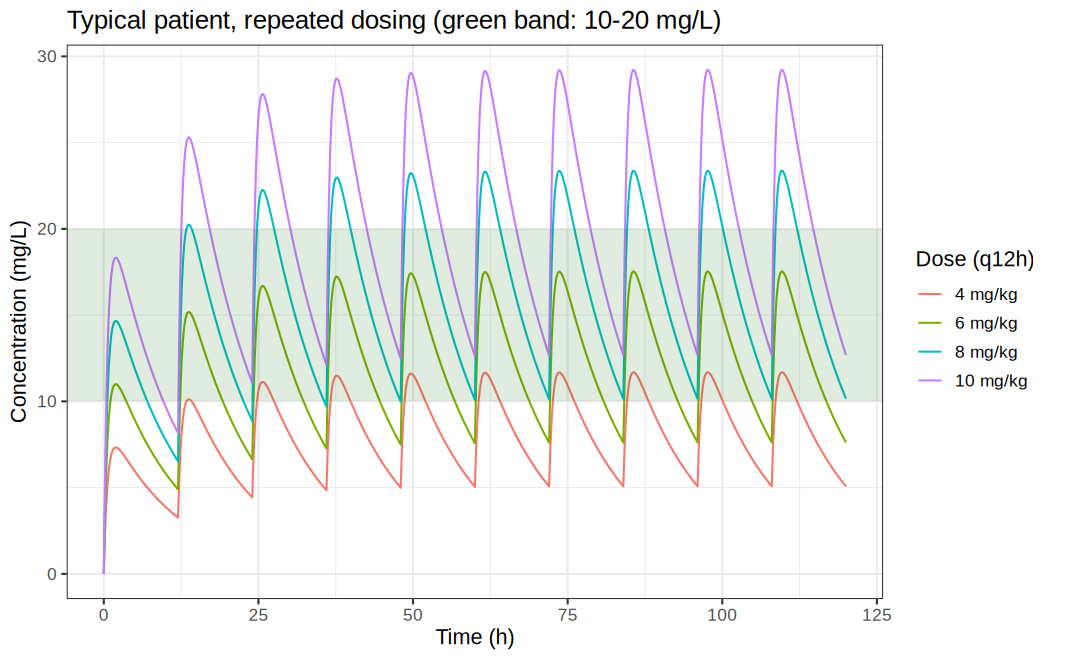

In [16]:
# 전형 환자(η=0)의 농도-시간 곡선
tt <- seq(0, ndose * tau, by = 0.2)
typ <- do.call(rbind, lapply(regimens, function(D) data.frame(
  dose = paste0(D, " mg/kg"), Time = tt,
  conc = conc_1cmt(tt, D, exp(th["lKa"]), exp(th["lKe"]),
                   exp(th["lCl"]) / exp(th["lKe"]), tau, ndose))))
typ$dose <- factor(typ$dose, levels = paste0(regimens, " mg/kg"))
ggplot(typ, aes(Time, conc, colour = dose)) + geom_line() +
  annotate("rect", xmin = -Inf, xmax = Inf, ymin = 10, ymax = 20, alpha = .12, fill = "darkgreen") +
  labs(x = "Time (h)", y = "Concentration (mg/L)", colour = "Dose (q12h)",
       title = "Typical patient, repeated dosing (green band: 10-20 mg/L)")

## 7. PK/PD 연결: Emax 모형과 목표 점유율 용량

자료가 없으므로 **가상 약물 X**의 PK/PD 자료를 직접 만들어 쓴다. 숫자는 설명용으로 정한 값이고 특정 약을 나타내지 않는다.

- PK: 1-구획 경구, 1일 1회. CL/F = 20 L/h, V/F = 400 L, ka = 1 /h, IIV(CL) 35%, IIV(V) 25%
- PD: 수용체 점유율 RO(%) = Emax · C / (EC50 + C), Emax = 100, 참값 EC50 = 6 ng/mL, 측정오차 SD 5%p
- 목표: 정상상태 최저농도에서 점유율 65% 이상, 최고농도에서 80% 이하 (항정신병약 D2 점유율에서 흔히 쓰는 창을 빌려 왔다)

순서: 자료 생성 → Emax 모형 적합(`nls`)으로 EC50 추정 → 추정 EC50로 용량별 목표 달성 비율 계산

,id,dose,time,conc,RO
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,6,157.6,12.568,69.79
2,1,6,154.7,14.646,64.17
3,2,6,162.0,12.009,56.08
4,2,6,147.2,21.571,72.05
5,3,1,155.8,1.932,24.18
6,3,1,154.3,2.050,24.71


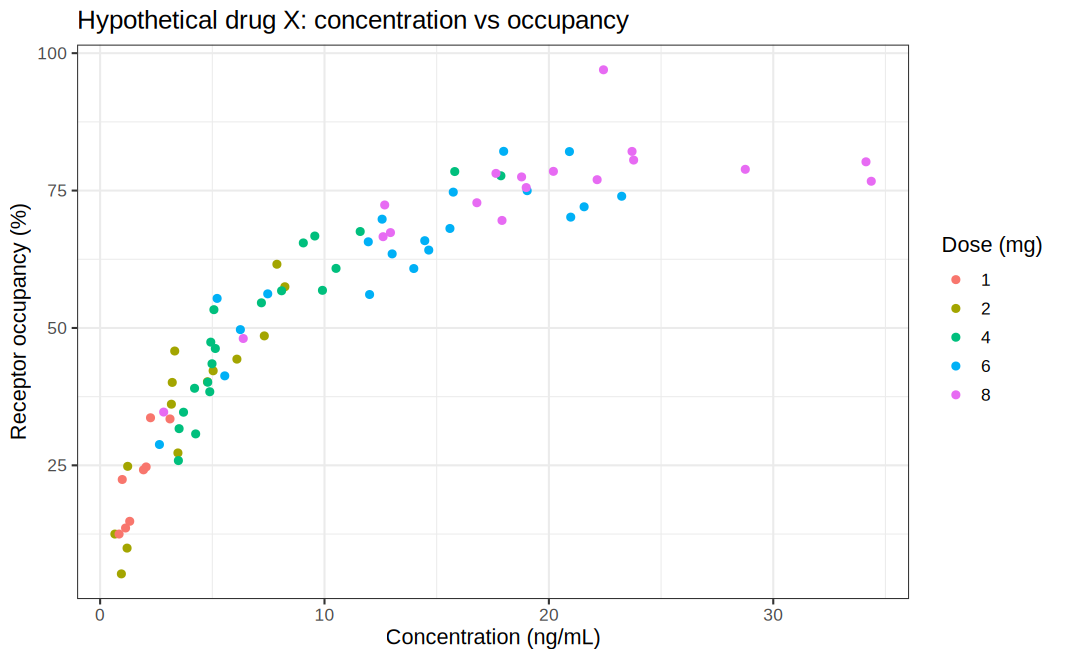

In [17]:
# 7-1. 가상 PK/PD 자료 생성 (40명, 용량 1–8 mg, 정상상태에서 임의 시점 2회 측정)
n_pd <- 40
true <- list(CL = 20, V = 400, ka = 1, EC50 = 6, Emax = 100)
pd_pts <- data.frame(id = 1:n_pd,
                     dose = sample(c(1, 2, 4, 6, 8), n_pd, replace = TRUE),
                     CL = true$CL * exp(rnorm(n_pd, 0, 0.35)),
                     V  = true$V  * exp(rnorm(n_pd, 0, 0.25)))
pd_pts$ke <- pd_pts$CL / pd_pts$V

pd_obs <- do.call(rbind, lapply(1:n_pd, function(i) {
  p <- pd_pts[i, ]
  tt <- 6 * 24 + runif(2, 0, 24)    # 7일째 하루 중 임의 시각
  # 용량 mg, 부피 L → mg/L, ×1000 하면 ng/mL
  c_ng <- 1000 * conc_1cmt(tt, p$dose, true$ka, p$ke, p$V, tau = 24, n = 7)
  ro <- true$Emax * c_ng / (true$EC50 + c_ng) + rnorm(2, 0, 5)
  data.frame(id = p$id, dose = p$dose, time = tt, conc = c_ng, RO = pmin(pmax(ro, 0), 100))
}))
head(pd_obs)

ggplot(pd_obs, aes(conc, RO)) + geom_point(aes(colour = factor(dose))) +
  labs(x = "Concentration (ng/mL)", y = "Receptor occupancy (%)", colour = "Dose (mg)", title = "Hypothetical drug X: concentration vs occupancy")

,Estimate,Std. Error,t value,Pr(>|t|)
EC50,6.273,0.1815,34.56,1.867e-49


,Estimate,Std. Error,t value,Pr(>|t|)
Emax,99.839,2.7210,36.69,5.856e-51
EC50,6.248,0.4677,13.36,7.423e-22


,df,AIC
,<dbl>,<dbl>
pd_fix,2,500.3
pd_free,3,502.3


참값 EC50 = 6  / 추정 EC50 = 6.27 ng/mL
65% 점유 농도 = 11.65 ng/mL, 80% 점유 농도 = 25.09 ng/mL


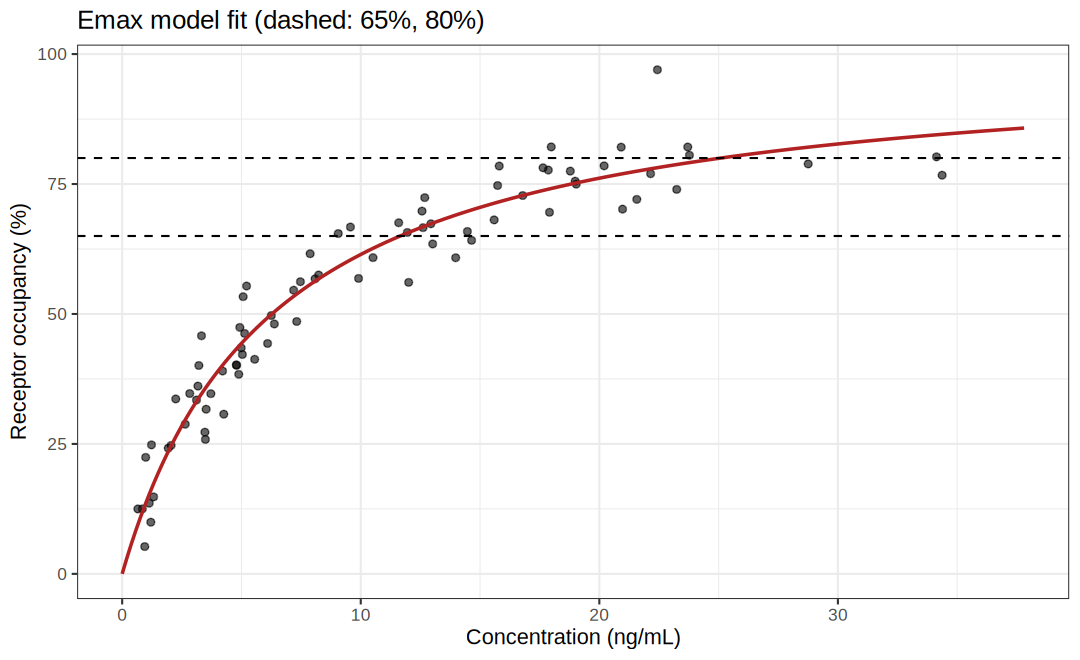

In [18]:
# 7-2. Emax 모형 적합: Emax 고정(=100) 모형과 Emax 추정 모형을 둘 다 본다
pd_fix <- nls(RO ~ 100 * conc / (EC50 + conc), data = pd_obs, start = list(EC50 = 3))
pd_free <- nls(RO ~ Emax * conc / (EC50 + conc), data = pd_obs,
               start = list(Emax = 90, EC50 = 3))
summary(pd_fix)$coefficients
summary(pd_free)$coefficients
AIC(pd_fix, pd_free)

ec50_hat <- coef(pd_fix)["EC50"]
cat("참값 EC50 =", true$EC50, " / 추정 EC50 =", round(ec50_hat, 2), "ng/mL\n")
# 목표 점유율에 필요한 농도: C = EC50 * RO / (100 - RO)
cat("65% 점유 농도 =", round(ec50_hat * 65 / 35, 2), "ng/mL,",
    "80% 점유 농도 =", round(ec50_hat * 80 / 20, 2), "ng/mL\n")

cc <- seq(0, max(pd_obs$conc) * 1.1, length.out = 200)
ggplot(pd_obs, aes(conc, RO)) + geom_point(alpha = .6) +
  geom_line(data = data.frame(conc = cc, RO = predict(pd_fix, newdata = data.frame(conc = cc))),
            colour = "firebrick", linewidth = 1) +
  geom_hline(yintercept = c(65, 80), linetype = 2) +
  labs(x = "Concentration (ng/mL)", y = "Receptor occupancy (%)", title = "Emax model fit (dashed: 65%, 80%)")

dose,in_window,under,over
<dbl>,<dbl>,<dbl>,<dbl>
1.0,0.0,100.0,0.0
1.5,0.0,100.0,0.0
2.0,0.0,100.0,0.0
2.5,0.0,100.0,0.0
3.0,0.2,99.8,0.0
3.5,1.2,98.8,0.0
4.0,2.4,97.5,0.1
4.5,4.4,94.8,0.9
5.0,5.9,91.4,3.0


창 안에 드는 비율이 가장 높은 용량: 6 mg/일


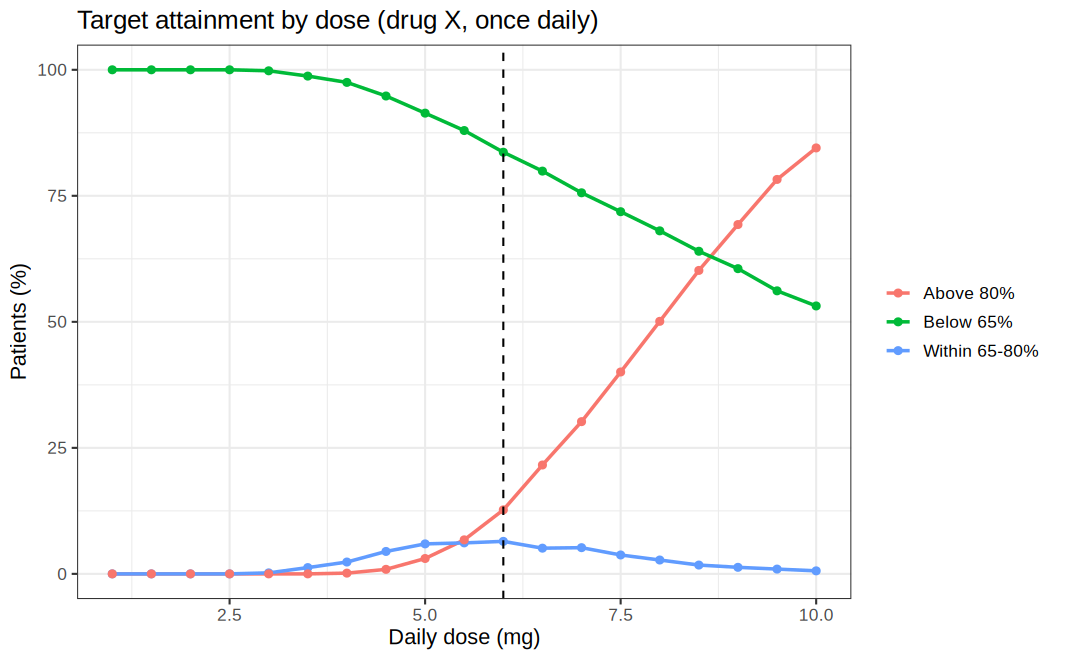

In [19]:
# 7-3. 용량 탐색: 가상 환자 2,000명에서 정상상태 최저/최고 점유율이 창(65–80%) 안에 드는 비율
n_v <- 2000
vp <- data.frame(CL = true$CL * exp(rnorm(n_v, 0, 0.35)),
                 V  = true$V  * exp(rnorm(n_v, 0, 0.25)))
vp$ke <- vp$CL / vp$V
dose_grid <- seq(1, 10, by = 0.5)
tg <- seq(6 * 24, 7 * 24, by = 0.5)

ro_fun <- function(c) 100 * c / (ec50_hat + c)
dose_res <- do.call(rbind, lapply(dose_grid, function(D) {
  cmat <- sapply(tg, function(t) 1000 * conc_1cmt(t, D, true$ka, vp$ke, vp$V, 24, 7))
  ro_min <- ro_fun(apply(cmat, 1, min)); ro_max <- ro_fun(apply(cmat, 1, max))
  data.frame(dose = D,
             in_window = 100 * mean(ro_min >= 65 & ro_max <= 80),
             under     = 100 * mean(ro_min < 65),
             over      = 100 * mean(ro_max > 80))
}))
round(dose_res, 1)
best_dose <- dose_res$dose[which.max(dose_res$in_window)]
cat("창 안에 드는 비율이 가장 높은 용량:", best_dose, "mg/일\n")

dl <- reshape(dose_res, direction = "long", varying = c("in_window", "under", "over"),
              v.names = "pct", timevar = "group", times = c("Within 65-80%", "Below 65%", "Above 80%"))
ggplot(dl, aes(dose, pct, colour = group)) + geom_line(linewidth = 1) + geom_point() +
  geom_vline(xintercept = best_dose, linetype = 2) +
  labs(x = "Daily dose (mg)", y = "Patients (%)", colour = NULL,
       title = "Target attainment by dose (drug X, once daily)")

1회 1일 투여로는 최저-최고 점유율 차이 때문에 창 안에 드는 비율이 높지 않다. 같은 1일 용량을 나눠 먹이면(12시간 간격) 어떻게 되는지 아래에서 비교한다.

regimen,in_window
<chr>,<dbl>
Once daily,6.45
Twice daily,35.95


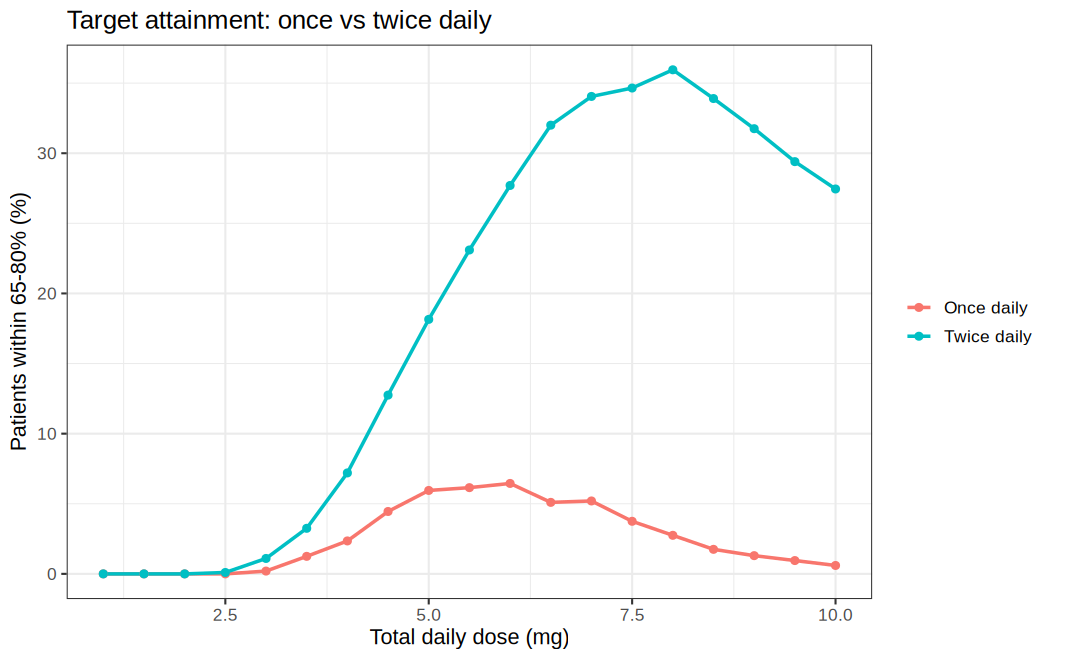

In [20]:
split_res <- do.call(rbind, lapply(c(24, 12), function(tau_x) {
  do.call(rbind, lapply(dose_grid, function(D) {
    n_x <- 7 * 24 / tau_x
    dd <- D * tau_x / 24
    tg_x <- seq(6 * 24, 7 * 24, by = 0.5)
    cmat <- sapply(tg_x, function(t) 1000 * conc_1cmt(t, dd, true$ka, vp$ke, vp$V, tau_x, n_x))
    ro_min <- ro_fun(apply(cmat, 1, min)); ro_max <- ro_fun(apply(cmat, 1, max))
    data.frame(regimen = ifelse(tau_x == 24, "Once daily", "Twice daily"), daily = D,
               in_window = 100 * mean(ro_min >= 65 & ro_max <= 80))
  }))
}))
ggplot(split_res, aes(daily, in_window, colour = regimen)) + geom_line(linewidth = 1) + geom_point() +
  labs(x = "Total daily dose (mg)", y = "Patients within 65-80% (%)", colour = NULL,
       title = "Target attainment: once vs twice daily")
aggregate(in_window ~ regimen, data = split_res, FUN = max)

결과 읽기: 1일 1회로는 어떤 용량에서도 창 안에 드는 환자가 최대 6% 정도에 그친다 (seed 2026 기준). 65–80% 창에 해당하는 농도 범위가 약 2배 폭밖에 안 되는데, 하루 한 번 투여 시 최고/최저 농도 차이가 그보다 크기 때문이다. 같은 총량을 둘로 나누면 달성 비율이 크게 오른다. 용량 최적화는 '몇 mg'뿐 아니라 '어떻게 나눠서'도 같이 봐야 한다는 점을 보여 주는 예시다.

## 8. 결과 저장과 정리

아래 셀은 결과 표를 CSV로 남긴다. Colab 왼쪽 파일 탭에서 내려받거나 Drive를 마운트해서 옮긴다.

In [21]:
dir.create("pkpd_results", showWarnings = FALSE)
write.csv(nca,       "pkpd_results/nca_theoph.csv", row.names = FALSE)
write.csv(ind_par,   "pkpd_results/individual_1cmt.csv", row.names = FALSE)
write.csv(pop_tab,   "pkpd_results/popPK_final.csv", row.names = FALSE)
write.csv(reg_sum,   "pkpd_results/regimen_theoph.csv", row.names = FALSE)
write.csv(dose_res,  "pkpd_results/dose_search_drugX.csv", row.names = FALSE)
list.files("pkpd_results")
sessionInfo()

[1] "dose_search_drugX.csv" "individual_1cmt.csv"   "nca_theoph.csv"       
[4] "popPK_final.csv"       "regimen_theoph.csv"

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] ggplot2_4.0.3 nlme_3.1-171 

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.7.3        cli_3.6.6          rlang_1.3.0       
 [5] generics_0.1.4   